<a href="https://colab.research.google.com/github/SitiMutmainah15/PEMBELAJARAN-MESIN_GENAP_2026/blob/main/JS10/JS10_LAB1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
	import numpy as np
	import matplotlib.pyplot as plt
	import pandas as pd
	import seaborn as sns

In [12]:
df = pd.read_csv('Iris.csv')
df = df.drop(columns=['Id'])
df.columns = range(5)

df.head()

,0,1,2,3,4
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


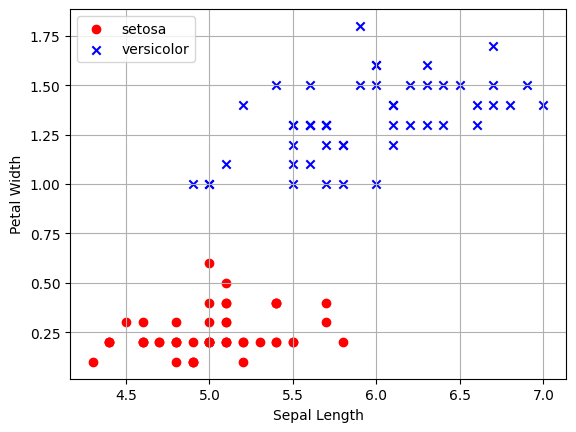

In [13]:
setosa = df[df[4] == 'Iris-setosa']
versicolor = df[df[4] == 'Iris-versicolor']
virginica = df[df[4] == 'Iris-virginica']

a, b = 0, 3

plt.scatter(setosa[a], setosa[b],
            color='red', marker='o', label='setosa')

plt.scatter(versicolor[a], versicolor[b],
            color='blue', marker='x', label='versicolor')

plt.xlabel('Sepal Length')
plt.ylabel('Petal Width')
plt.legend(loc='upper left')
plt.grid()
plt.show()

In [20]:
class Perceptron(object):
    def __init__(self, eta=0.01, n_iter=10):
        self.eta = eta
        self.n_iter = n_iter

    def fit(self, X, y):

        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[0] += update
                self.w_[1:] += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

In [21]:
y = df.iloc[0:100, 4].values
y = np.where(y == 'Iris-setosa', -1, 1)
X = df.iloc[0:100, [0, 3]].values

In [22]:
print("Ukuran X:", X.shape)
print("Ukuran y:", y.shape)
print("Label:", np.unique(y))
print("Contoh data X:")
print(X[:5])

Ukuran X: (100, 2)
Ukuran y: (100,)
Label: [-1  1]
Contoh data X:
[[5.1 0.2]
 [4.9 0.2]
 [4.7 0.2]
 [4.6 0.2]
 [5.  0.2]]


In [23]:
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)

In [24]:
print("Bobot dan bias:", ppn.w_)
print("Jumlah error setiap epoch:", ppn.errors_)
print("Pelatihan model selesai!")

Bobot dan bias: [-0.4  -0.1   1.12]
Jumlah error setiap epoch: [2, 2, 2, 3, 2, 1, 0, 0, 0, 0]
Pelatihan model selesai!


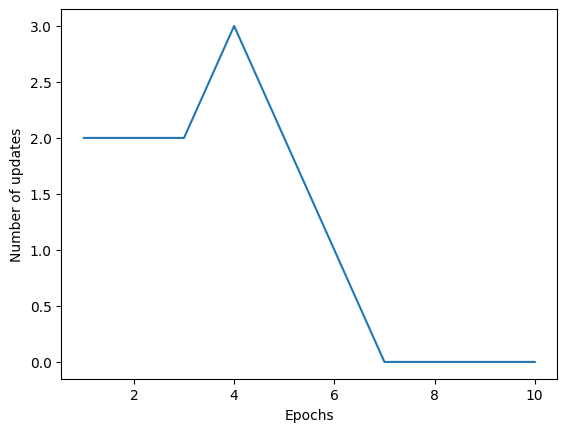

In [25]:
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_)
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.show()

In [26]:
for i, error in enumerate(ppn.errors_, start=1):
    print(f"Epoch {i}: {error} error")

Epoch 1: 2 error
Epoch 2: 2 error
Epoch 3: 2 error
Epoch 4: 3 error
Epoch 5: 2 error
Epoch 6: 1 error
Epoch 7: 0 error
Epoch 8: 0 error
Epoch 9: 0 error
Epoch 10: 0 error


In [27]:
from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('r', 'b', 'g', 'k', 'grey')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision regions
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx1, xx2 = np.meshgrid(
        np.arange(x1_min, x1_max, resolution),
        np.arange(x2_min, x2_max, resolution)
    )

    # predict class labels
    Z = classifier.predict(
        np.array([xx1.ravel(), xx2.ravel()]).T
    )
    Z = Z.reshape(xx1.shape)

    # draw the contour
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for i, cl in enumerate(np.unique(y)):
        plt.scatter(
            x=X[y == cl, 0],
            y=X[y == cl, 1],
            alpha=0.8,
            color=cmap(i),
            marker=markers[i],
            label=cl
        )

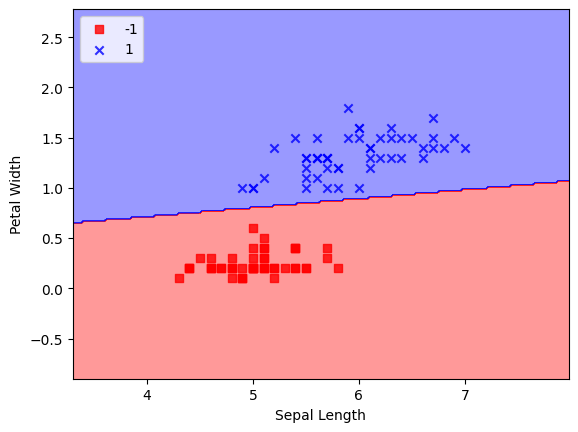

In [28]:
plot_decision_regions(X, y, classifier=ppn)

plt.xlabel('Sepal Length')
plt.ylabel('Petal Width')
plt.legend(loc='upper left')
plt.show()